In [50]:
%pip install kaleido
%pip install plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


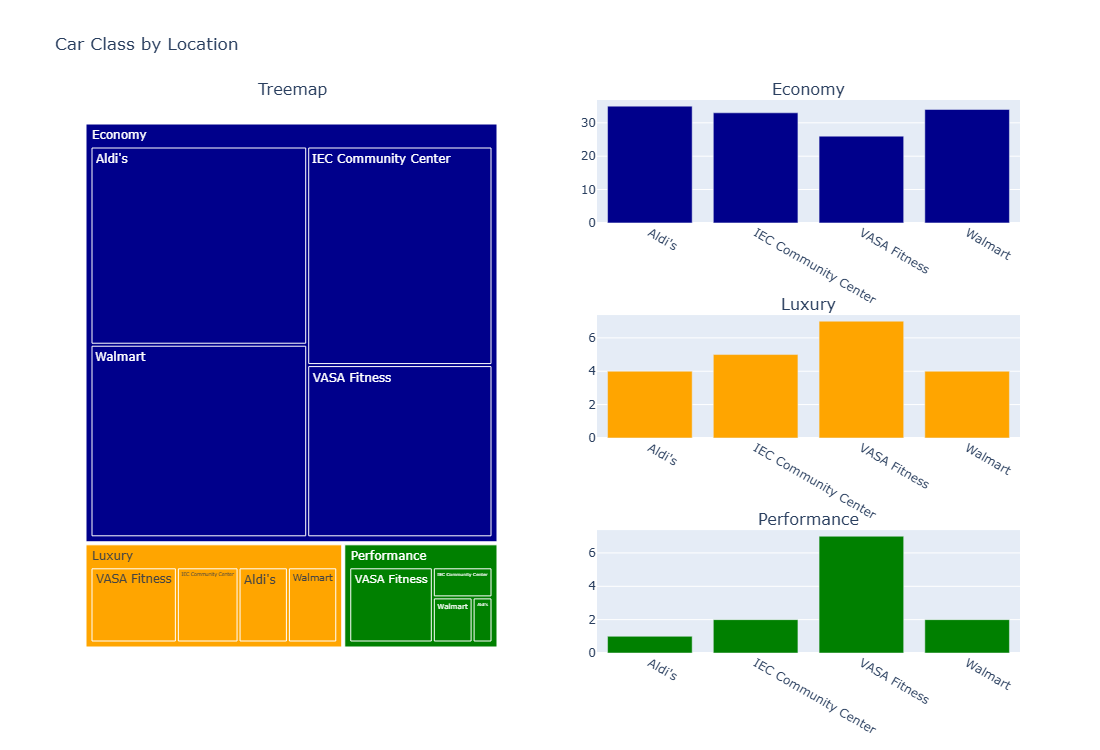

In [51]:

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import Image, display

cars = pd.read_csv("CarsCleaned.csv")
counts = cars.groupby(["Class", "Location"]).size().reset_index(name="Count")

colors = {"Economy": "darkblue", "Luxury": "orange", "Performance": "green"}
classes = ["Economy", "Luxury", "Performance"]

cartree = px.treemap(counts, path=["Class", "Location"], values="Count", color="Class", color_discrete_map=colors)

carvisclassbylocation = make_subplots(
    rows=3, cols=2,
    specs=[[{"type": "domain", "rowspan": 3}, {"type": "xy"}],
           [None, {"type": "xy"}],
           [None, {"type": "xy"}]],
    subplot_titles=["Treemap", *classes]
)

carvisclassbylocation.add_trace(cartree.data[0], row=1, col=1)
carvisclassbylocation.data[0].textinfo = "label"

for i, c in enumerate(classes, 1):
    subset = counts[counts["Class"] == c]
    carvisclassbylocation.add_trace(go.Bar(x=subset["Location"], y=subset["Count"], marker_color=colors[c]), row=i, col=2)

carvisclassbylocation.update_layout(title="Car Class by Location", width=1100, height=750, showlegend=False)

carvisclassbylocation.write_image("ClassByLocVis.png")
display(Image("ClassByLocVis.png"))

In [52]:
%pip install holoviews matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import holoviews as hv

hv.extension("matplotlib")

cars = pd.read_csv("CarsCleaned.csv")

top10 = cars["Make"].value_counts().head(10).index

counts = (
    cars[cars["Make"].isin(top10)]
    .groupby(["Make", "Type"])
    .size()
    .reset_index(name="Count")
)

matrix = hv.HeatMap(
    counts,
    kdims=["Make", "Type"],
    vdims="Count"
).opts(
    title="Make Type Frequency Matrix",
    fig_size=180,
    xrotation=45,
    cmap="Blues",
    colorbar=True
)

carsankey = hv.Sankey(
    counts,
    kdims=["Make", "Type"],
    vdims="Count"
).opts(
    title="Make by Type",
    fig_size=180,
    label_position="right"
)

combined = (matrix + carsankey).cols(1).opts(
    hv.opts.Layout(vspace=0.7)
)

hv.save(combined, "MakeByTypeVis.png")

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W

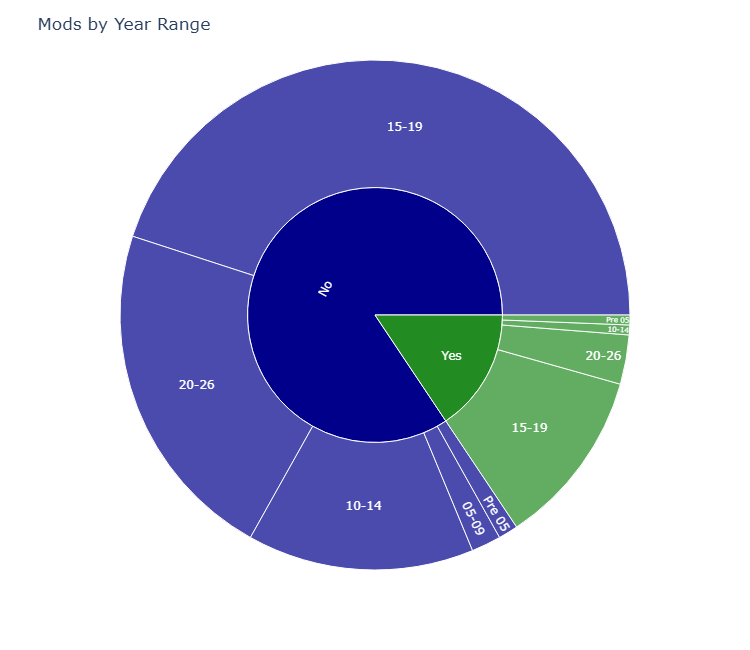

In [ ]:
import pandas as pd
import plotly.express as px
from IPython.display import Image, display

cars = pd.read_csv("CarsCleaned.csv")

carsunburst = px.sunburst(
    cars,
    path=["Modified", "Year_Range"],
    color="Modified",
    color_discrete_map={
        "Yes": "forestgreen",
        "No": "darkblue"
    }
)

carsunburst.update_traces(
    textinfo="label"
)

carsunburst.update_layout(
    title="Mods by Year Range",
    width=750,
    height=650
)

carsunburst.write_image("modsunburst.png")
display(Image("modsunburst.png"))

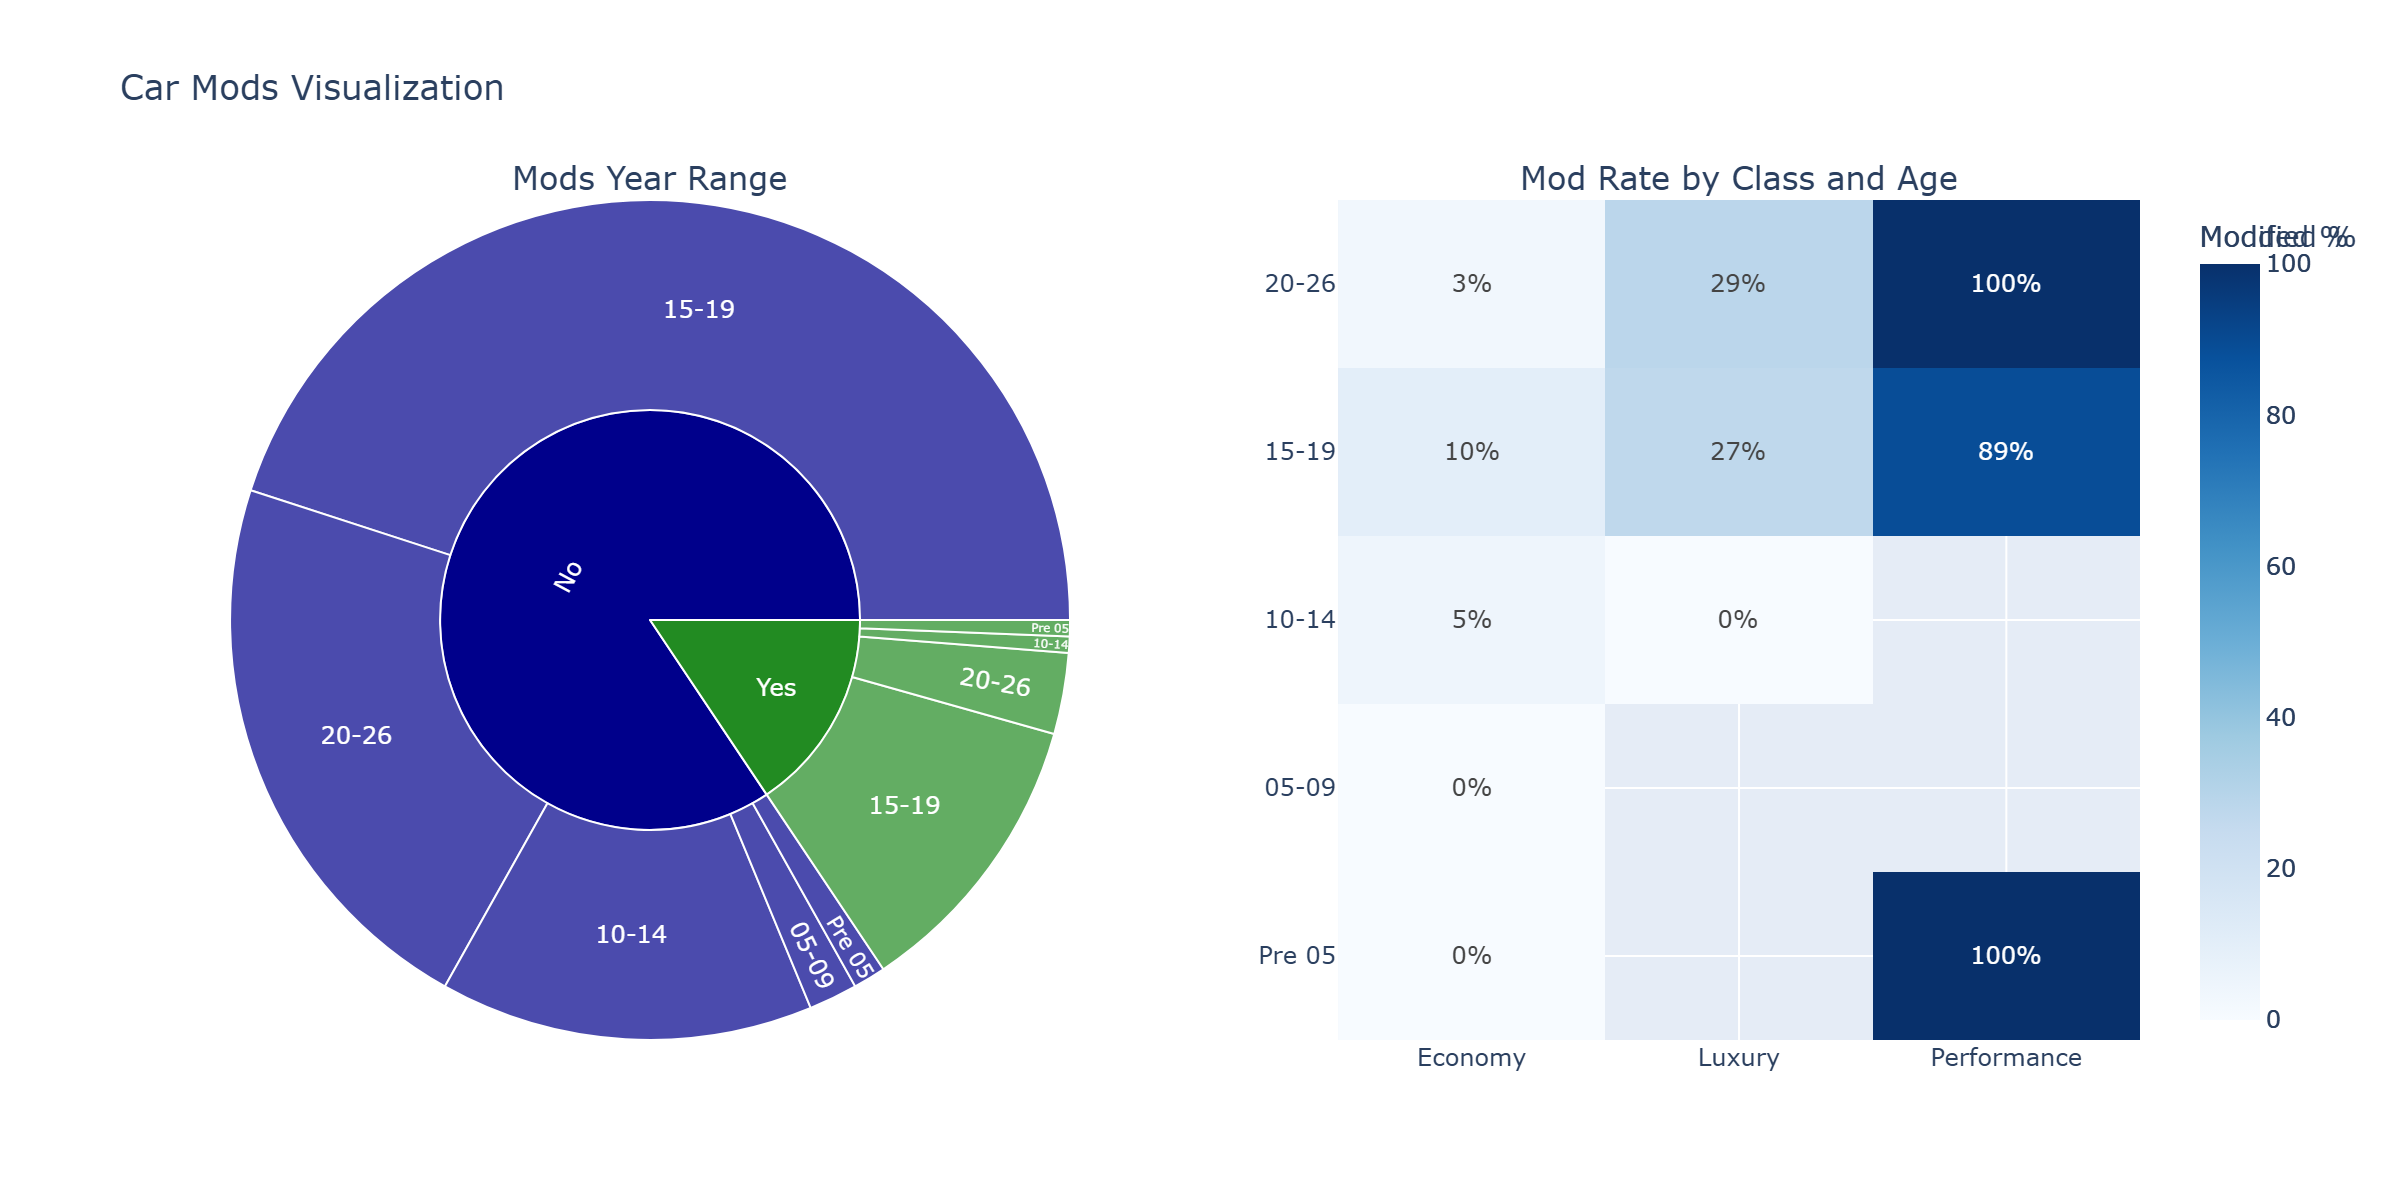

In [ ]:

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import Image, display

cars = pd.read_csv("CarsCleaned.csv")

sunburst = px.sunburst(
    cars,
    path=["Modified", "Year_Range"],
    color="Modified",
    color_discrete_map={"Yes": "forestgreen", "No": "darkblue"}
)

rates = cars.groupby(["Year_Range", "Class"])["Is Modified"].mean() * 100

carmatrix = rates.unstack().reindex(
    index=["Pre 05", "05-09", "10-14", "15-19", "20-26"],
    columns=["Economy", "Luxury", "Performance"]
)

ClassByAge = make_subplots( rows=1, cols=2, specs=[[{"type": "domain"}, {"type": "xy"}]], subplot_titles=["Mods Year Range", "Mod Rate by Class and Age"], column_widths=[0.55, 0.45])

ClassByAge.add_trace(sunburst.data[0], row=1, col=1)

ClassByAge.add_trace(
    go.Heatmap(
        x=carmatrix.columns,
        y=carmatrix.index,
        z=carmatrix.values,
        colorscale="Blues",
        colorbar=dict(title="Modified %"),
    ),
    row=1, col=2
)

ClassByAge.update_layout(
    title="Car Mods Visualization",
    width=1200,
    height=600
)

carmatrix = rates.unstack().reindex(index=["Pre 05", "05-09", "10-14", "15-19", "20-26"], columns=["Economy", "Luxury", "Performance"])

ClassByAge.add_trace(
    go.Heatmap(
        x=carmatrix.columns.tolist(),
        y=carmatrix.index.tolist(),
        z=carmatrix.values,
        colorscale="Blues",
        zmin=0,
        zmax=100,
        text=[
            [f"{v:.0f}%" if pd.notna(v) else "" for v in row]
            for row in carmatrix.values
        ],
        texttemplate="%{text}",
        colorbar=dict(title="Modded %")
    ),
    row=1, col=2
)

ClassByAge.update_yaxes(
    type="category",
    row=1,
    col=2
)
ClassByAge.write_image("carmodsvis.png", scale=2)
display(Image("carmodsvis.png"))


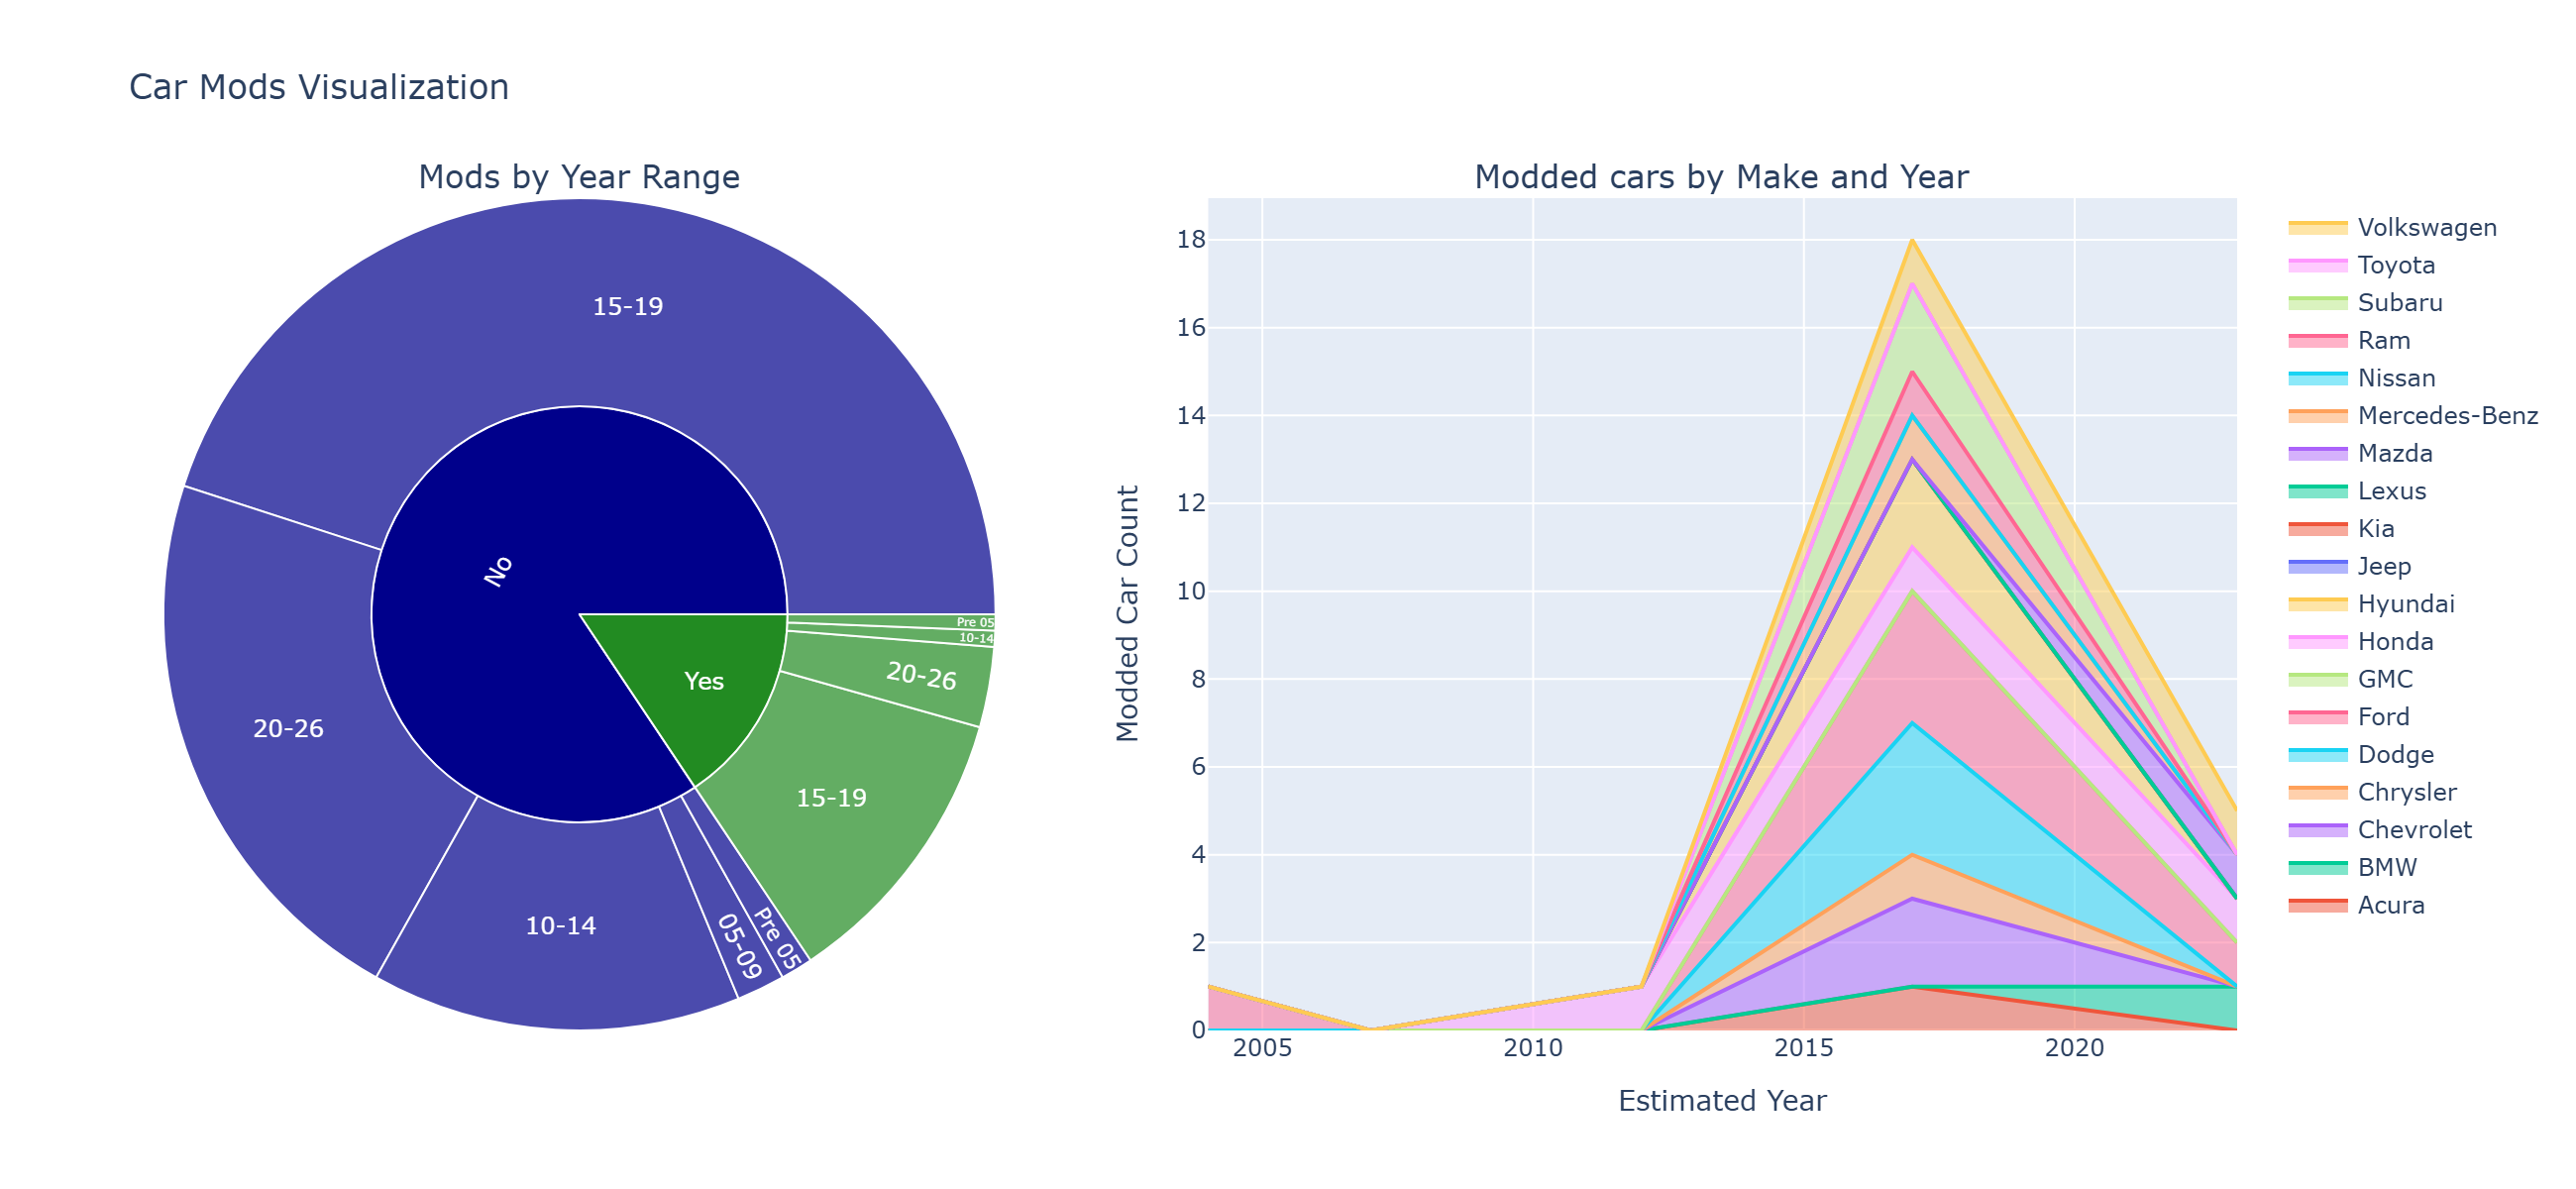

In [ ]:

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import Image, display

cars = pd.read_csv("CarsCleaned.csv")
sunburst = px.sunburst(
    cars,
    path=["Modified", "Year_Range"],
    color="Modified",
    color_discrete_map={"Yes": "forestgreen", "No": "darkblue"}
)

streams = cars.pivot_table(index="Estimated Year Midpoint", columns="Make", values="Is Modified", aggfunc="sum", fill_value=0).sort_index()

Modsvis = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "domain"}, {"type": "xy"}]],
    subplot_titles=["Mods by Year Range", "Modded cars by Make and Year"],
    column_widths=[0.45, 0.55]
)

Modsvis.add_trace(sunburst.data[0], row=1, col=1)

for make in streams.columns:
    Modsvis.add_trace(
        go.Scatter(x=streams.index, y=streams[make], name=make, mode="lines",stackgroup="one"),
        row=1, col=2
    )

Modsvis.update_layout(title="Car Mods Visualization", width=1300, height=600, showlegend=True
)

Modsvis.update_xaxes(title_text="Estimated Year", row=1, col=2)
Modsvis.update_yaxes(title_text="Modded Car Count", row=1, col=2)

Modsvis.write_image("carmodsvisV1.png", scale=2)
display(Image("carmodsvisV1.png"))
